# Regression: comparing the 4 models
Reads the saved results of notebooks 01-04 (run those first), then repeats the training many times
(5-fold cross-validation + 10 random 80/20 splits) with the same settings (`Common/model_zoo.py`).
Charts: `Results/Regression/05_Model_Comparison/`

In [1]:
# Setup: imports, data and the fixed 80/20 train/test split (seed 42)
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "src", "Common")))

import numpy as np
from project import SEED, Outputs, regression_data
import matplotlib.pyplot as plt
import pandas as pd
import plots
from data import kfold_indices, train_test_split_scratch
from metrics import mae, mse, r2, rmse
from model_zoo import regression_models
from project import load_json

out = Outputs("Regression", "05_Model_Comparison")
d = regression_data()
print(f"train {d.X_train.shape} | test {d.X_test.shape} | target int.rate | {len(d.feature_cols)} features")


NAMES = {
    "1. Simple Linear (FICO)": "01_Simple_Linear_Regression",
    "2. Multiple Linear": "02_Multiple_Linear_Regression",
    "3. Polynomial (deg 2)": "03_Polynomial_Regression",
    "4. Gradient Boosting (better)": "04_Gradient_Boosting_Regressor",
}
gbr = load_json("Regression", NAMES["4. Gradient Boosting (better)"], "chosen_settings.json")
models = regression_models(gbr)
metrics = pd.concat([pd.read_csv(os.path.join(out.results, "..", f, "metrics.csv")) for f in NAMES.values()])
preds = {n: np.load(os.path.join(out.results, "..", f, "predictions.npz")) for n, f in NAMES.items()}
histories = {
    n: pd.read_csv(os.path.join(out.results, "..", f, "loss_curve.csv"))["train_loss_mse"].values
    for n, f in NAMES.items()
}
print("GBR settings from notebook 04:", gbr)

train (7662, 20) | test (1916, 20) | target int.rate | 20 features
GBR settings from notebook 04: {'n_estimators': 600, 'max_depth': 4, 'learning_rate': 0.05}


## Benchmark on the test set (+ a baseline that always predicts the mean)

                               Train loss (MSE)  Test loss (MSE)  Test RMSE  Test MAE   Test R2
Model                                                                                          
Baseline (predict the mean)            0.000729         0.000689   0.026255  0.020980 -0.001287
1. Simple Linear (FICO)                0.000357         0.000334   0.018269  0.013871  0.515213
2. Multiple Linear                     0.000241         0.000230   0.015181  0.011411  0.665245
3. Polynomial (deg 2)                  0.000308         0.000282   0.016779  0.012667  0.591023
4. Gradient Boosting (better)          0.000091         0.000165   0.012860  0.009023  0.759776

                               Scratch R2  scikit-learn R2    Difference
Model                                                                   
1. Simple Linear (FICO)          0.515213         0.515213 -2.220446e-16
2. Multiple Linear               0.665245         0.664842  4.032980e-04
3. Polynomial (deg 2)            0.

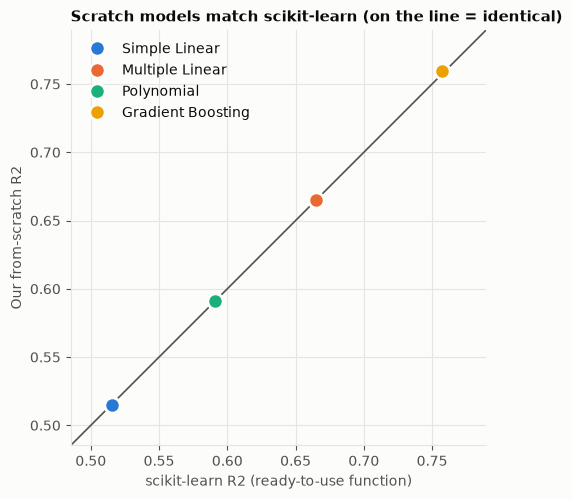

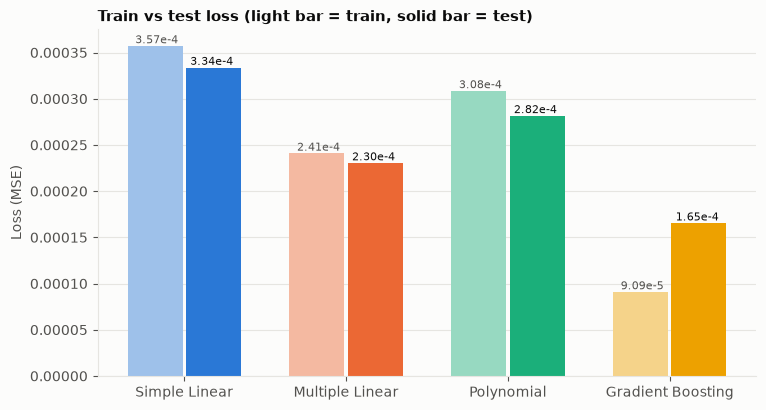

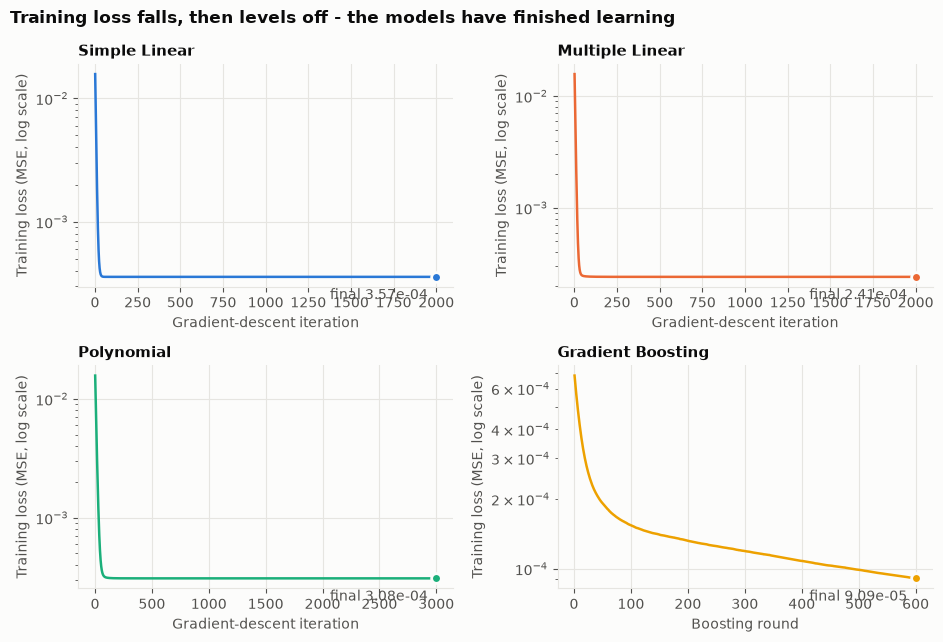

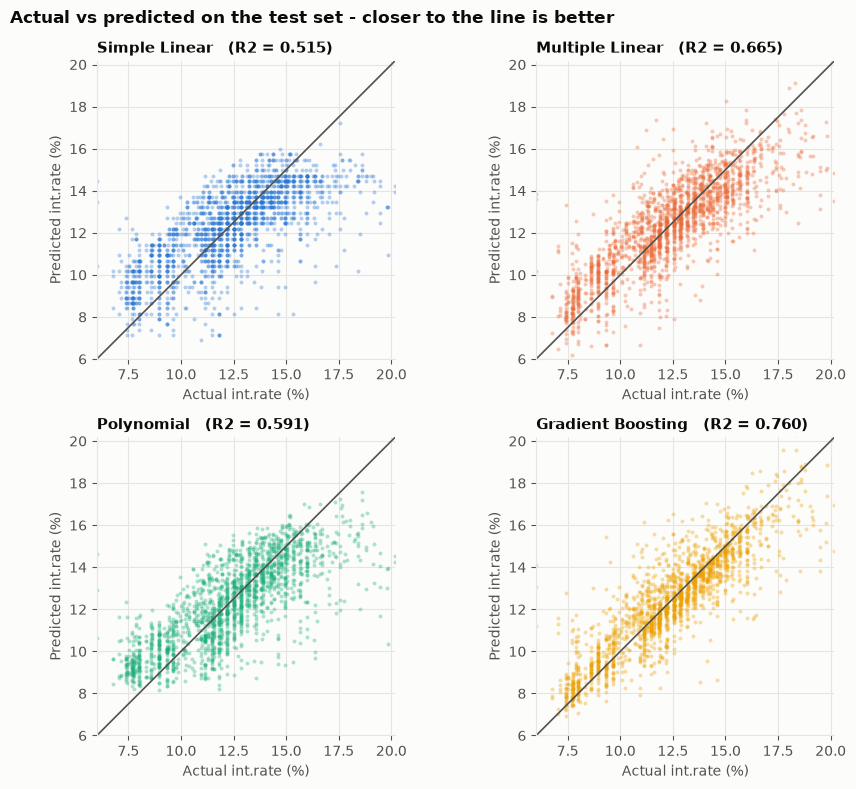

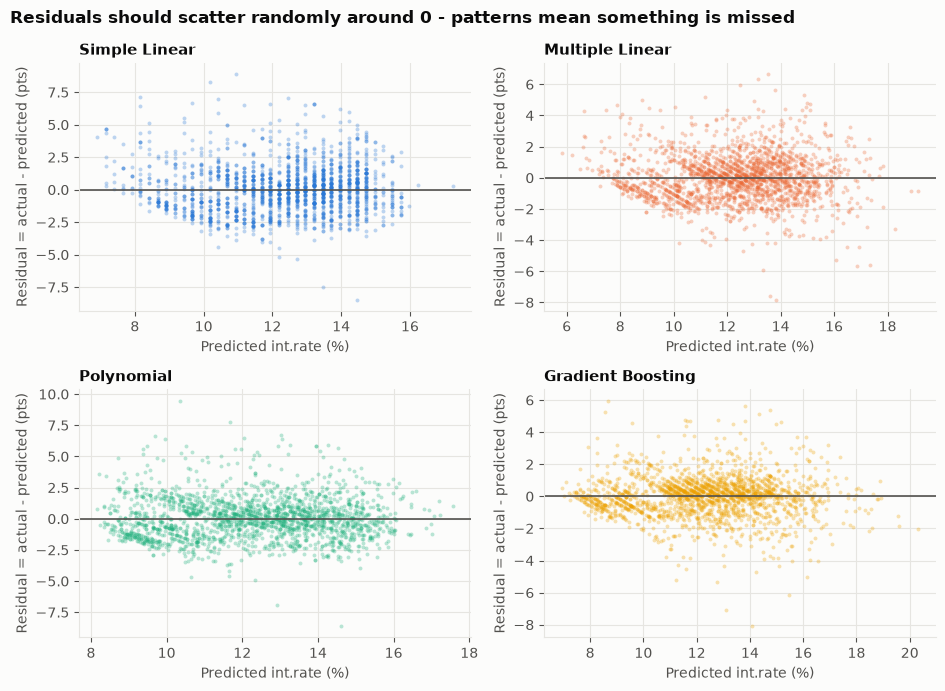

In [2]:
base = np.full_like(d.y_test, d.y_train.mean())
baseline = {
    "Model": "Baseline (predict the mean)",
    "Train loss (MSE)": mse(d.y_train, np.full_like(d.y_train, d.y_train.mean())),
    "Test loss (MSE)": mse(d.y_test, base),
    "Test RMSE": rmse(d.y_test, base),
    "Test MAE": mae(d.y_test, base),
    "Test R2": r2(d.y_test, base),
}
results = pd.concat([pd.DataFrame([baseline]), metrics], ignore_index=True)
print(
    results.drop(columns=["scikit-learn R2", "Difference"])
    .set_index("Model")
    .to_string(float_format=lambda v: f"{v:.6f}")
)

ver = metrics.set_index("Model")[["Test R2", "scikit-learn R2", "Difference"]].rename(columns={"Test R2": "Scratch R2"})
ver.to_csv(out.table("scratch_vs_sklearn.csv"), index_label="Model")
print("\n" + ver.to_string())
plots.plot_scratch_vs_sklearn(ver, out.image("scratch_vs_sklearn.png"))
loss_table = metrics[["Model", "Train loss (MSE)", "Test loss (MSE)"]]
loss_table.to_csv(out.table("loss_table.csv"), index=False)
plots.plot_train_vs_test_loss(loss_table, out.image("train_vs_test_loss.png"))
plots.plot_loss_curves(histories, out.image("loss_curves.png"))
test_preds = {n: p["p_test"] for n, p in preds.items()}
plots.plot_actual_vs_predicted(
    d.y_test, test_preds, {n: r2(d.y_test, p) for n, p in test_preds.items()}, out.image("actual_vs_predicted.png")
)
plots.plot_residuals(test_preds, d.y_test, out.image("residuals.png"))

## 5-fold cross-validation (every row is a test row exactly once)

  fold 1/5 done


  fold 2/5 done


  fold 3/5 done


  fold 4/5 done


  fold 5/5 done


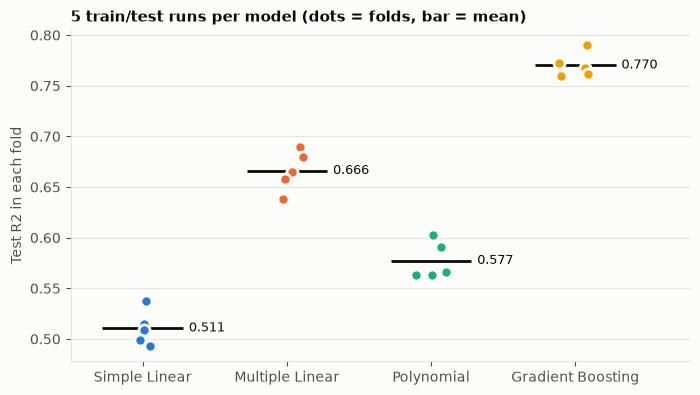

                               CV R2 mean  CV R2 std
1. Simple Linear (FICO)          0.510617   0.015336
2. Multiple Linear               0.666023   0.017674
3. Polynomial (deg 2)            0.577247   0.016622
4. Gradient Boosting (better)    0.770198   0.011015


In [3]:
cv_scores = {name: [] for name in models}
for k, (tr, te) in enumerate(kfold_indices(len(d.y), 5, SEED), 1):
    for name, make in models.items():
        cv_scores[name].append(r2(d.y[te], make().fit(d.X[tr], d.y[tr], d.feature_cols).predict(d.X[te])))
    print(f"  fold {k}/5 done")
cv = pd.DataFrame(
    {
        "CV R2 mean": {n: np.mean(v) for n, v in cv_scores.items()},
        "CV R2 std": {n: np.std(v) for n, v in cv_scores.items()},
    }
)
pd.DataFrame(cv_scores, index=[f"fold {k}" for k in range(1, 6)]).to_csv(out.table("cv_folds.csv"), index_label="fold")
plots.plot_cv_per_fold(cv_scores, out.image("cv_r2_per_fold.png"))
print(cv.to_string())

## Batch runs: 10 random 80/20 splits (same protocol as the single split, new seed each time)

  split 1/10 done


  split 2/10 done


  split 3/10 done


  split 4/10 done


  split 5/10 done


  split 6/10 done


  split 7/10 done


  split 8/10 done


  split 9/10 done


  split 10/10 done
                                R2 mean  RMSE mean  MAE mean     R2 SD   RMSE SD    MAE SD
Baseline (predict the mean)   -0.001217   0.026748  0.021351  0.001271  0.000255  0.000303
1. Simple Linear (FICO)        0.511802   0.018675  0.014300  0.018910  0.000408  0.000261
2. Multiple Linear             0.671300   0.015324  0.011539  0.011286  0.000314  0.000198
3. Polynomial (deg 2)          0.579389   0.017331  0.013252  0.022435  0.000483  0.000304
4. Gradient Boosting (better)  0.776415   0.012637  0.008869  0.008973  0.000261  0.000170

better model minus Multiple Linear: +0.1051 R2 on average (SD 0.0061), better in 10 of 10 splits


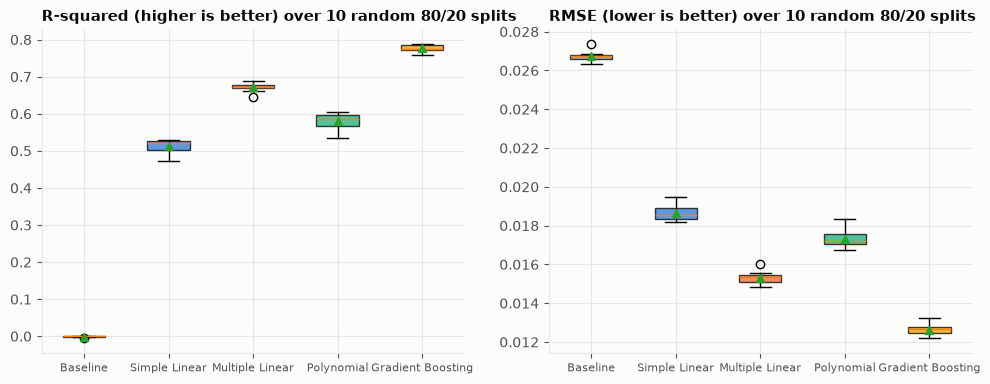

In [4]:
N_BATCH = 10
batch = {n: {"R2": [], "RMSE": [], "MAE": []} for n in ["Baseline (predict the mean)"] + list(models)}
for b in range(N_BATCH):
    Xa, Xb, ya, yb = train_test_split_scratch(d.X, d.y, test_size=0.2, seed=1000 + b)
    predictions = {"Baseline (predict the mean)": np.full_like(yb, ya.mean())}
    predictions.update({n: make().fit(Xa, ya, d.feature_cols).predict(Xb) for n, make in models.items()})
    for n, p in predictions.items():
        for k, f in (("R2", r2), ("RMSE", rmse), ("MAE", mae)):
            batch[n][k].append(f(yb, p))
    print(f"  split {b + 1}/{N_BATCH} done")
batch_tbl = pd.DataFrame(
    {n: {f"{k} mean": np.mean(v[k]) for k in v} | {f"{k} SD": np.std(v[k]) for k in v} for n, v in batch.items()}
).T
batch_tbl.to_csv(out.table("batch_runs.csv"), index_label="Model")
print(batch_tbl.to_string())
gb, ml = np.array(batch["4. Gradient Boosting (better)"]["R2"]), np.array(batch["2. Multiple Linear"]["R2"])
print(
    f"\nbetter model minus Multiple Linear: {np.mean(gb - ml):+.4f} R2 on average (SD {np.std(gb - ml):.4f}), "
    f"better in {(gb > ml).sum()} of {N_BATCH} splits"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
names = list(batch)
for ax, k, t in ((axes[0], "R2", "R-squared (higher is better)"), (axes[1], "RMSE", "RMSE (lower is better)")):
    bp = ax.boxplot(
        [batch[n][k] for n in names],
        tick_labels=[plots.SHORT.get(n, "Baseline") for n in names],
        patch_artist=True,
        showmeans=True,
    )
    for patch, n in zip(bp["boxes"], names):
        patch.set_facecolor(plots.MODEL_COLORS.get(n, plots.NEUTRAL))
        patch.set_alpha(0.75)
    ax.set_title(f"{t} over {N_BATCH} random 80/20 splits")
    ax.tick_params(axis="x", labelsize=8)
plots._save(fig, out.image("batch_runs.png"))

## Final table: every model, every metric

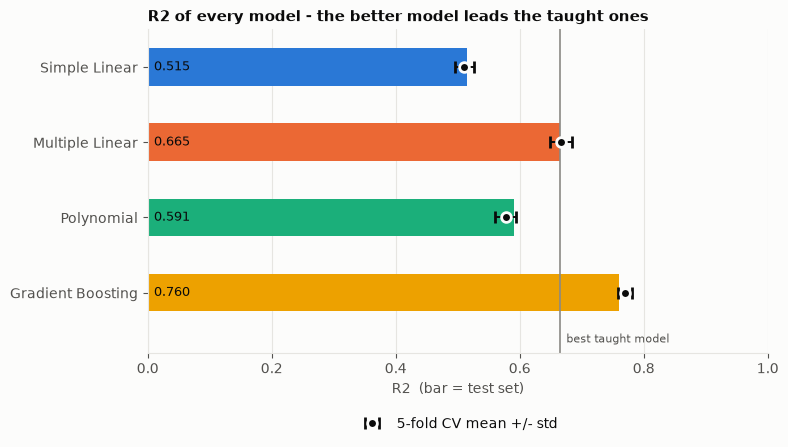

                               Train loss (MSE)  Test loss (MSE)  Test RMSE  Test MAE  Test R2  CV R2 mean  CV R2 std  R2 gain vs best taught model
Model                                                                                                                                              
1. Simple Linear (FICO)                  0.0004           0.0003     0.0183    0.0139   0.5152      0.5106     0.0153                       -0.1500
2. Multiple Linear                       0.0002           0.0002     0.0152    0.0114   0.6652      0.6660     0.0177                        0.0000
3. Polynomial (deg 2)                    0.0003           0.0003     0.0168    0.0127   0.5910      0.5772     0.0166                       -0.0742
4. Gradient Boosting (better)            0.0001           0.0002     0.0129    0.0090   0.7598      0.7702     0.0110                        0.0945

best taught model test R2 = 0.6652; better model = 0.7598


In [5]:
table = metrics.set_index("Model").drop(columns=["scikit-learn R2", "Difference"]).join(cv)
taught_best = table.loc[["1. Simple Linear (FICO)", "2. Multiple Linear", "3. Polynomial (deg 2)"], "Test R2"].max()
table["R2 gain vs best taught model"] = table["Test R2"] - taught_best
table.to_csv(out.table("benchmark_all_metrics.csv"))
plots.plot_r2_comparison(table, out.image("r2_comparison.png"))
print(table.to_string(float_format=lambda v: f"{v:.4f}"))
print(
    f"\nbest taught model test R2 = {taught_best:.4f}; better model = {table.loc['4. Gradient Boosting (better)', 'Test R2']:.4f}"
)